# RuO₂ / TiO₂: dry, step, adsorbed monolayer and layered water

Four cases share the same Poisson-terraced solid (`alpha = 0.15`) at **20 keV**.
The second half repeats them on an atomically flat surface (`alpha = 0`):

| Case | Physical water model | Adsorption / first-layer parameter |
|---|---|---|
| 1. Dry | No attached water; vacuum ambient | — |
| 2. Step | Smooth onset into bulk water | `A0 = 0` |
| 3. Step + 1 ML | Same onset plus one Gaussian adsorbed layer | `A0 = sites_per_cell = 1` |
| 4. Layered | Gaussian layers that broaden into bulk water | `A0 = 1` (relative first-layer weight) |

**Coverage convention:** here one full monolayer means one H₂O molecule per
reference surface cell, i.e. one fully occupied adsorption site per cell.
The step parameter is a molecule count, not a fractional coverage:
$A_0=\theta N_{\rm sites}$ and $\Gamma=A_0/A_{\rm cell}$.
Change `sites_per_cell` for a different surface-site convention or supercell.
This is an explicit example normalization, not a fitted RuO₂ adsorption capacity.
The integral of the added density is checked below.

Water onset, the adsorbed Gaussian centre (`adsorption_position="onset"`),
and the first layered-water centre are all **3 Å above each local terrace**.
The common initial width is 0.60 Å. Layered water uses 2.8 Å spacing and
0.40 Å cumulative broadening. The spacing is the same literature-inspired
value as in the [damping example](layered_water_damping.ipynb),
not a RuO₂-specific measurement.

The physical families are `step` and `layered`. The step cases use the
analytic **tanh interface reference**; their physical onset is erf.
Layered water uses a sharp equimolar reference plus its closed-form Hosemann DWBA
perturbation. All water uses the molecular O + 2H form factor.


In [1]:
from pathlib import Path
import copy
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "orgui").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from examples.CTR.water_models_example import create_example
from orgui.datautils.xrayutils.CTRuc import WaterModel
from orgui.datautils.xrayutils.CTRfilm import PoissonSurface

dry = create_example("step", A0=0.)
next(c for c in dry.uc_surface_list if isinstance(c, PoissonSurface)).attach_water(None)
dry.apply_stacking()
cell = dry.uc_bulk
height = cell.volume / cell.uc_area  # Angstrom normal repeat height
sites_per_cell = 1.0
coverage_ML = 1.0
onset, spacing, sigma0, sigma_bar = 3.0, 2.8, 0.60, 0.40  # Angstrom
models = {"1. Dry": dry}
intrinsic = {}
for label, kind, A0 in (
    ("2. Step", "step", 0.),
    ("3. Step + 1 ML", "step", coverage_ML * sites_per_cell),
    ("4. Layered", "layered", 1.),
):
    water = WaterModel(cell.a.copy(), np.rad2deg(cell.alpha), kind,
                       optical_reference="tanh" if kind == "step" else "sharp",
                       name=kind.replace(" ", "_") + "_water")
    water.adsorption_position = "onset"
    water.setWaterParameters(onset/height, spacing/height, sigma0/height,
                             sigma_bar/height, A0)
    water.setEnergy(cell._E)  # eV at the core API boundary
    intrinsic[label] = water
    model = copy.deepcopy(dry)
    next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).attach_water(copy.deepcopy(water))
    model.apply_stacking()
    models[label] = model

# Validate the excess molecular count, including the molecular form-factor widths.
z_check = np.linspace(-20., 50., 7001)
plain, adsorbed = intrinsic["2. Step"], intrinsic["3. Step + 1 ML"]
excess = adsorbed.zDensity_G(z_check, 0., 0.) - plain.zDensity_G(z_check, 0., 0.)
f_molecule_0 = plain.bulk_density / plain.pw
count = simpson(excess, x=z_check) * plain.uc_area / f_molecule_0
np.testing.assert_allclose(count, coverage_ML*sites_per_cell, rtol=1e-8, atol=1e-10)
print(f"Reference surface area = {cell.uc_area:.4f} Å²")
print(f"1 ML = {sites_per_cell/cell.uc_area:.5f} H2O/Å²; integrated excess = {count.real:.8f} H2O/cell")
colors = ["#333333", "#0072B2", "#D55E00", "#009E73"]
styles = [":", "--", "-.", "-"]


Reference surface area = 19.5394 Å²
1 ML = 0.05118 H2O/Å²; integrated excess = 1.00000000 H2O/cell


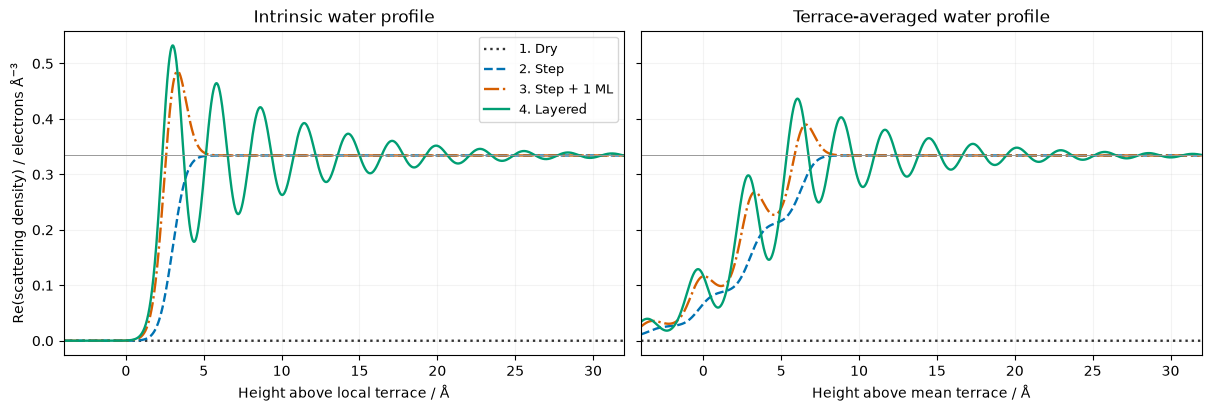

In [2]:
surface = next(c for c in dry.uc_surface_list if isinstance(c, PoissonSurface))
terrace_heights, probabilities, _ = surface.terrace_distribution()
mean_height = terrace_heights @ probabilities
z = np.linspace(-4., 32., 1801)
fig_density, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True,
                                constrained_layout=True)
for (label, model), color, style in zip(models.items(), colors, styles):
    if label == "1. Dry":
        local = averaged = np.zeros_like(z)
    else:
        water = intrinsic[label]
        local = water.zDensity_G(z, 0., 0.).real
        # Independent terrace average; attachment placements are generated by DWBA.
        averaged = sum(p*water.zDensity_G(z+mean_height-h, 0., 0.)
                       for h, p in zip(terrace_heights, probabilities)).real
    for ax, density in zip(axes, (local, averaged)):
        ax.plot(z, density, color=color, ls=style, lw=1.7, label=label)
axes[0].set(title="Intrinsic water profile", xlabel="Height above local terrace / Å",
            ylabel=r"Re(scattering density) / electrons Å$^{-3}$")
axes[1].set(title="Terrace-averaged water profile", xlabel="Height above mean terrace / Å")
axes[0].legend(fontsize=9)
for ax in axes:
    ax.axhline(plain.bulk_density.real, color="0.6", lw=.7)
    ax.set_xlim(-4., 32.)
    ax.grid(alpha=.15)
plt.show()


## Full CTRs and separate water signal

The first three panels show $|F_{\rm effective}|^2$ from the **complete coherent
DWBA amplitude** $r_0+\delta r_{\rm solid}+\delta r_{\rm water}$, divided by
the DWBA amplitude prefactor. The calculation uses equal local incident and
exit angles, s polarization, and one common observation plane above all
profiles. Each case uses its own ambient: vacuum for dry, bulk water otherwise.
Curves are not independently rescaled.

The final panel shows the full **water-only kinematic** Fourier intensity,
including terrace averaging. It is a component diagnostic, not a separate
DWBA intensity to add to the solid curve. Dry water scattering is exactly
zero and cannot appear on a logarithmic axis. Since these water models are
laterally uniform, direct water scattering is zero on 01L and 11L; their
water dependence is mediated by the optical fields.


00L 1. Dry: 0.15 s
00L 2. Step: 0.22 s


00L 3. Step + 1 ML: 0.20 s
00L 4. Layered: 0.20 s


01L 1. Dry: 0.16 s


01L 2. Step: 0.24 s


01L 3. Step + 1 ML: 0.22 s
01L 4. Layered: 0.21 s


11L 1. Dry: 0.23 s


11L 2. Step: 0.22 s
11L 3. Step + 1 ML: 0.18 s


11L 4. Layered: 0.20 s


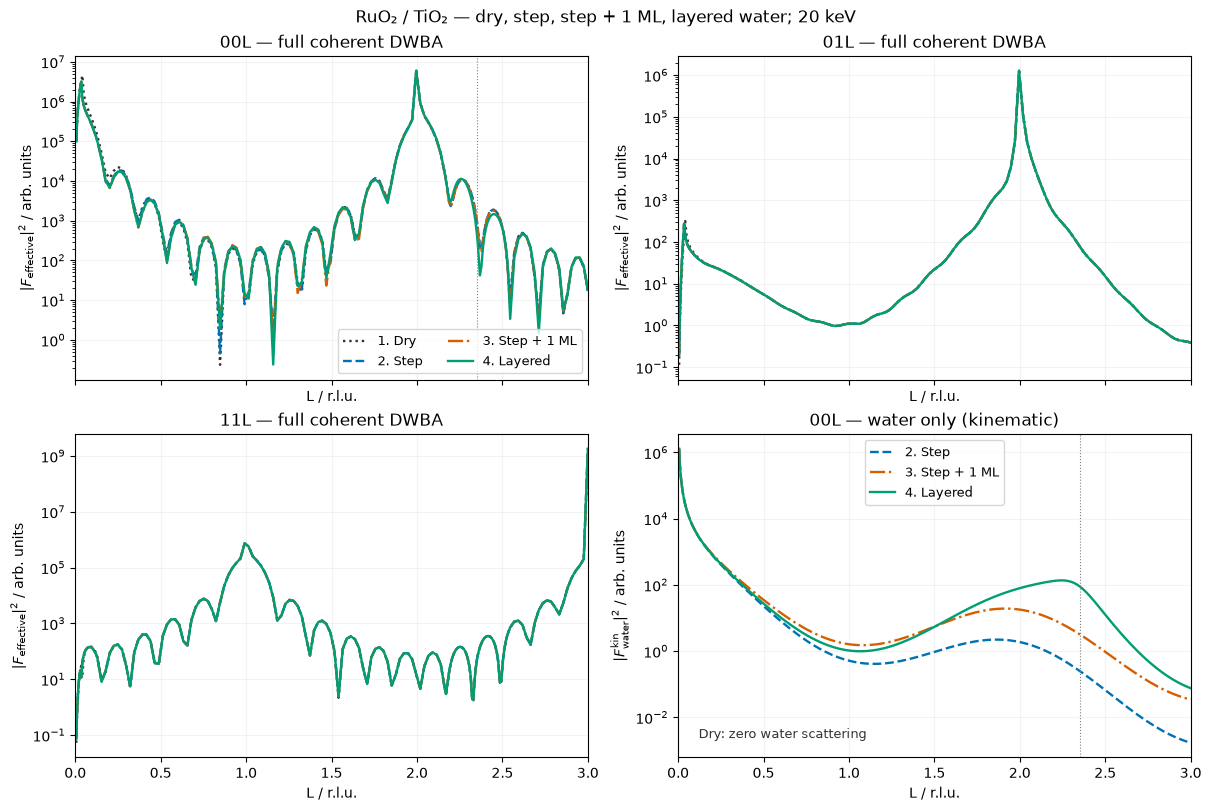

In [3]:
layer_L = height/spacing
L = np.unique(np.r_[np.geomspace(.006, .12, 18), np.linspace(.13, 3., 121),
                     np.linspace(layer_L-.18, layer_L+.18, 41)])
rods = [(0, 0), (0, 1), (1, 1)]
results = {}
for h, k in rods:
    for label, model in models.items():
        start = time.perf_counter()
        model.dwba.set_ctr_geometry(equal_angles=True, rods=[(h, k)])
        result = model.dwba.evaluate(np.full_like(L, h), np.full_like(L, k), L)
        assert np.isfinite(result.total_amplitude).all()
        np.testing.assert_allclose(sum(c.F_h for c in result.contributions),
                                   result.F_h, rtol=1e-9, atol=1e-9)
        water_terms = [c.F_h for c in result.contributions if c.role == "water"]
        assert bool(water_terms) == (label != "1. Dry")
        if (h, k) == (0, 0) and water_terms:
            attached = next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).water
            check_z = np.linspace(-4., 32., 101)
            expected = sum(p*intrinsic[label].zDensity_G(check_z+mean_height-t, 0., 0.)
                           for t, p in zip(terrace_heights, probabilities))
            np.testing.assert_allclose(attached.zDensity_G(check_z+mean_height, 0., 0.),
                                       expected, rtol=1e-12, atol=1e-12)
        if (h, k) != (0, 0) and water_terms:
            np.testing.assert_allclose(water_terms, 0., atol=1e-12)
        results[h, k, label] = result
        print(f"{h}{k}L {label}: {time.perf_counter()-start:.2f} s")

common_plane = max(float(np.atleast_1d(r.prepared.field_i.z_reference)[0])
                   for r in results.values()) + 8.
fig_ctrs, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True,
                             constrained_layout=True)
ctr_intensity = {}
for ax, (h, k) in zip(axes.flat, rods):
    for label, color, style in zip(models, colors, styles):
        result = results[h, k, label]
        p = result.prepared
        origin = float(np.atleast_1d(p.field_i.z_reference)[0])
        phase = np.exp(-1j*p.k0*p.reference.n[0]*(np.sin(p.alpha_i)+np.sin(p.alpha_f))
                       *(common_plane-origin))
        intensity = abs(result.F_effective*phase)**2
        ctr_intensity[h, k, label] = intensity
        ax.semilogy(L, intensity, color=color, ls=style, lw=1.7, label=label)
    ax.set(title=f"{h}{k}L — full coherent DWBA",
           ylabel=r"$|F_{\rm effective}|^2$ / arb. units")
for label, color, style in zip(models, colors, styles):
    if label == "1. Dry":
        continue
    water = next(c for c in models[label].uc_surface_list if isinstance(c, PoissonSurface)).water
    F_water = water.F_uc(np.zeros_like(L), np.zeros_like(L), L)
    assert np.isfinite(F_water).all()
    axes[1, 1].semilogy(L, abs(F_water)**2, color=color, ls=style, lw=1.7, label=label)
axes[1, 1].set(title="00L — water only (kinematic)",
               ylabel=r"$|F_{\rm water}^{\rm kin}|^2$ / arb. units")
axes[1, 1].text(.04, .06, "Dry: zero water scattering", transform=axes[1, 1].transAxes,
                fontsize=9, color=colors[0])
for ax in (axes[0, 0], axes[1, 1]):
    ax.axvline(layer_L, color="0.5", lw=.8, ls=":")
for ax in axes.flat:
    ax.set(xlim=(0., 3.), xlabel="L / r.l.u.")
    ax.grid(alpha=.15)
axes[0, 0].legend(fontsize=9, ncol=2)
axes[1, 1].legend(fontsize=9)
fig_ctrs.suptitle("RuO₂ / TiO₂ — dry, step, step + 1 ML, layered water; 20 keV")
plt.show()

# Optional: save the four complete models as .xtal files.
# for slug, model in zip(("dry", "step", "step_1ML", "layered"), models.values()):
#     model.toFile(root / f"examples/CTR/RuO2_TiO2_comparison_{slug}.xtal")


## Atomically flat counterpart

`PoissonSurface.alpha` is the fraction of the growth/etching process assigned
to Poisson roughening, not an atomic Gaussian width. Setting it to zero at
the existing integer etch depth, $W=-6$, leaves a **single terrace height**.
The mean film thickness, solid atomic displacement parameters, water onset,
monolayer coverage, and intrinsic water widths remain unchanged. This isolates
the effect of terrace-height dispersion; it does not remove atomic thermal motion.

The code checks that the flat surface has zero height variance and the same
mean height as the rough surface. It then repeats all four full CTRs and the
water-only diagnostic. The original rough comparison above is retained.


Terrace RMS height: rough 3.2564 Å; flat 0.0000 Å
Mean terrace height: rough 36.000800 Å; flat 36.000800 Å


Flat 00L 1. Dry: 0.22 s


Flat 00L 2. Step: 0.25 s


Flat 00L 3. Step + 1 ML: 0.22 s


Flat 00L 4. Layered: 0.26 s
Flat 01L 1. Dry: 0.18 s


Flat 01L 2. Step: 0.19 s
Flat 01L 3. Step + 1 ML: 0.14 s


Flat 01L 4. Layered: 0.13 s
Flat 11L 1. Dry: 0.14 s


Flat 11L 2. Step: 0.15 s
Flat 11L 3. Step + 1 ML: 0.12 s


Flat 11L 4. Layered: 0.12 s


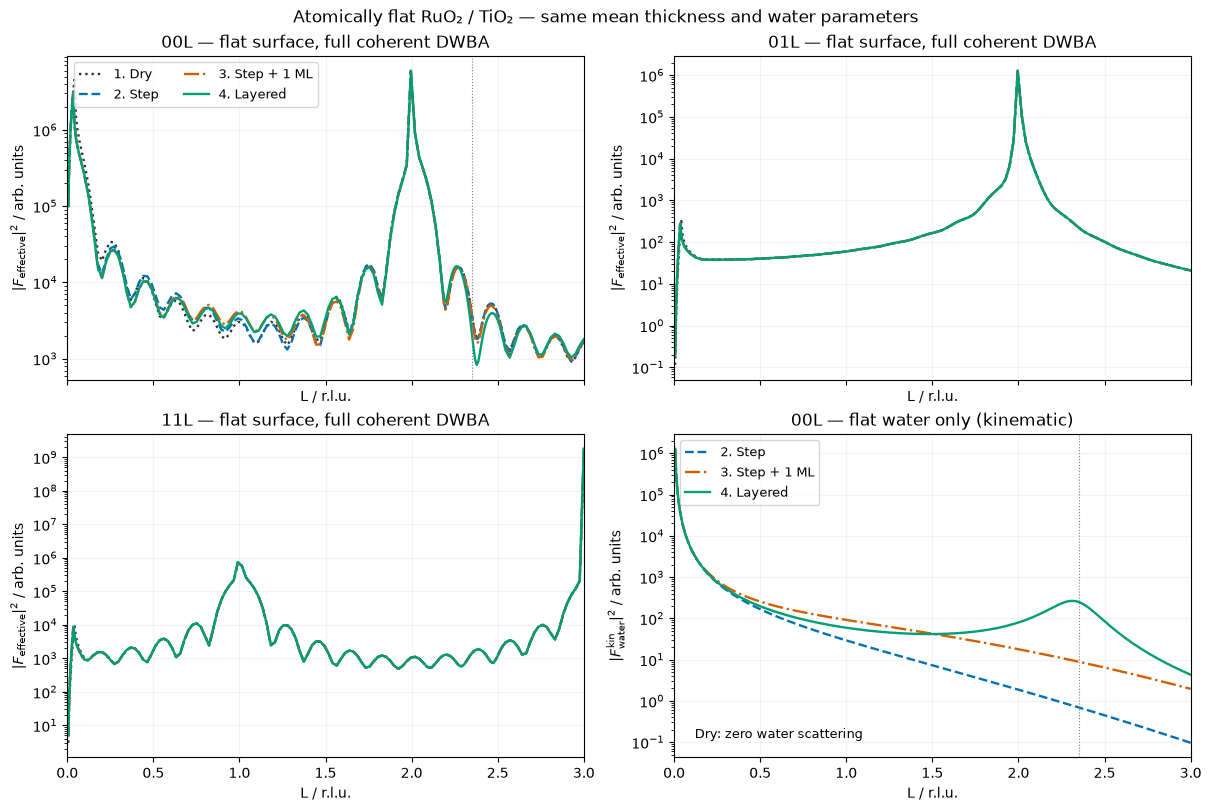

In [4]:
smooth_models = {}
smooth_heights = {}
for label, original in models.items():
    model = copy.deepcopy(original)
    surface = next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface))
    assert surface.basis[0] == -6. and surface.basis[2] == 0.
    surface.basis[1] = 0.  # No Poisson roughening; integer W gives one height.
    model.apply_stacking()
    heights_flat, weights_flat, _ = surface.terrace_distribution()
    mean_flat = heights_flat @ weights_flat
    variance_flat = weights_flat @ (heights_flat-mean_flat)**2
    np.testing.assert_allclose(variance_flat, 0., atol=1e-12)
    np.testing.assert_allclose(mean_flat, mean_height, atol=1e-7, rtol=0.)
    smooth_heights[label] = mean_flat
    smooth_models[label] = model
rough_rms = np.sqrt(probabilities @ (terrace_heights-mean_height)**2)
print(f"Terrace RMS height: rough {rough_rms:.4f} Å; flat {np.sqrt(variance_flat):.4f} Å")
print(f"Mean terrace height: rough {mean_height:.6f} Å; flat {mean_flat:.6f} Å")

smooth_results = {}
for h, k in rods:
    for label, model in smooth_models.items():
        start = time.perf_counter()
        model.dwba.set_ctr_geometry(equal_angles=True, rods=[(h, k)])
        result = model.dwba.evaluate(np.full_like(L, h), np.full_like(L, k), L)
        assert np.isfinite(result.total_amplitude).all()
        np.testing.assert_allclose(sum(c.F_h for c in result.contributions),
                                   result.F_h, rtol=1e-9, atol=1e-9)
        water_terms = [c.F_h for c in result.contributions if c.role == "water"]
        assert bool(water_terms) == (label != "1. Dry")
        if (h, k) != (0, 0) and water_terms:
            np.testing.assert_allclose(water_terms, 0., atol=1e-12)
        if (h, k) == (0, 0) and water_terms:
            water = next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).water
            np.testing.assert_allclose(water.zDensity_G(z+smooth_heights[label], 0., 0.),
                                       intrinsic[label].zDensity_G(z, 0., 0.), rtol=1e-12, atol=1e-12)
        smooth_results[h, k, label] = result
        print(f"Flat {h}{k}L {label}: {time.perf_counter()-start:.2f} s")

# One common observation plane for BOTH rough and flat calculations.
comparison_plane = max(float(np.atleast_1d(r.prepared.field_i.z_reference)[0])
                       for r in (*results.values(), *smooth_results.values())) + 8.
comparison_intensity = {}
for surface_name, surface_results in (("Rough", results), ("Flat", smooth_results)):
    for key, result in surface_results.items():
        p = result.prepared
        origin = float(np.atleast_1d(p.field_i.z_reference)[0])
        phase = np.exp(-1j*p.k0*p.reference.n[0]*(np.sin(p.alpha_i)+np.sin(p.alpha_f))
                       *(comparison_plane-origin))
        comparison_intensity[surface_name, *key] = abs(result.F_effective*phase)**2

fig_smooth, axes_smooth = plt.subplots(2, 2, figsize=(12, 8), sharex=True,
                                      constrained_layout=True)
for ax, (h, k) in zip(axes_smooth.flat, rods):
    for label, color, style in zip(models, colors, styles):
        ax.semilogy(L, comparison_intensity["Flat", h, k, label],
                    color=color, ls=style, lw=1.7, label=label)
    ax.set(title=f"{h}{k}L — flat surface, full coherent DWBA",
           ylabel=r"$|F_{\rm effective}|^2$ / arb. units")
water_F = {}
for surface_name, surface_models in (("Rough", models), ("Flat", smooth_models)):
    for label, model in surface_models.items():
        if label == "1. Dry":
            continue
        water = next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).water
        water_F[surface_name, label] = water.F_uc(np.zeros_like(L), np.zeros_like(L), L)
for label, color, style in zip(models, colors, styles):
    if label != "1. Dry":
        axes_smooth[1, 1].semilogy(L, abs(water_F["Flat", label])**2,
                                  color=color, ls=style, lw=1.7, label=label)
axes_smooth[1, 1].set(title="00L — flat water only (kinematic)",
                      ylabel=r"$|F_{\rm water}^{\rm kin}|^2$ / arb. units")
axes_smooth[1, 1].text(.04, .06, "Dry: zero water scattering",
                       transform=axes_smooth[1, 1].transAxes, fontsize=9)
for ax in (axes_smooth[0, 0], axes_smooth[1, 1]):
    ax.axvline(layer_L, color="0.5", lw=.8, ls=":")
for ax in axes_smooth.flat:
    ax.set(xlim=(0., 3.), xlabel="L / r.l.u.")
    ax.grid(alpha=.15)
axes_smooth[0, 0].legend(fontsize=9, ncol=2)
axes_smooth[1, 1].legend(fontsize=9)
fig_smooth.suptitle("Atomically flat RuO₂ / TiO₂ — same mean thickness and water parameters")
plt.show()


## Does roughness hide the water?

For laterally averaged water in the kinematic diagnostic, terrace averaging gives

$$F_{\rm water}^{\rm rough}(q_z)=F_{\rm water}^{\rm intrinsic}(q_z)
\sum_j p_j e^{iq_z h_j}.$$

The intensity attenuation is $|T(q_z)|^2=|\sum_jp_je^{iq_zh_j}|^2$.
It depends on momentum transfer and can recover near terrace-periodicity
conditions, so it is not a universal constant or a monotonic envelope.
The calculation below verifies this factor against all three water models.

For the **full coherent CTR**, use each surface's wet/dry ratio. Roughness
changes the solid signal and its interference with water too, so attenuation
of the isolated water signal does not imply the same attenuation of the
relative change in total intensity. Ratios at very deep dry minima are
masked using a stated intensity floor; an experimental detection threshold
would additionally require uncertainties and instrumental resolution.


At qz=2pi/d (L=2.35025): water intensity rough/flat = 0.3612
Removing terraces increases the isolated water intensity by 2.77 times there.
Rough dry-intensity floor for ratios: 0.056422
  2. Step: wet/dry at L=2.35025 = 0.9961
  3. Step + 1 ML: wet/dry at L=2.35025 = 0.8912
  4. Layered: wet/dry at L=2.35025 = 0.4880
Flat dry-intensity floor for ratios: 0.056504
  2. Step: wet/dry at L=2.35025 = 0.9916
  3. Step + 1 ML: wet/dry at L=2.35025 = 0.9023
  4. Layered: wet/dry at L=2.35025 = 0.5578


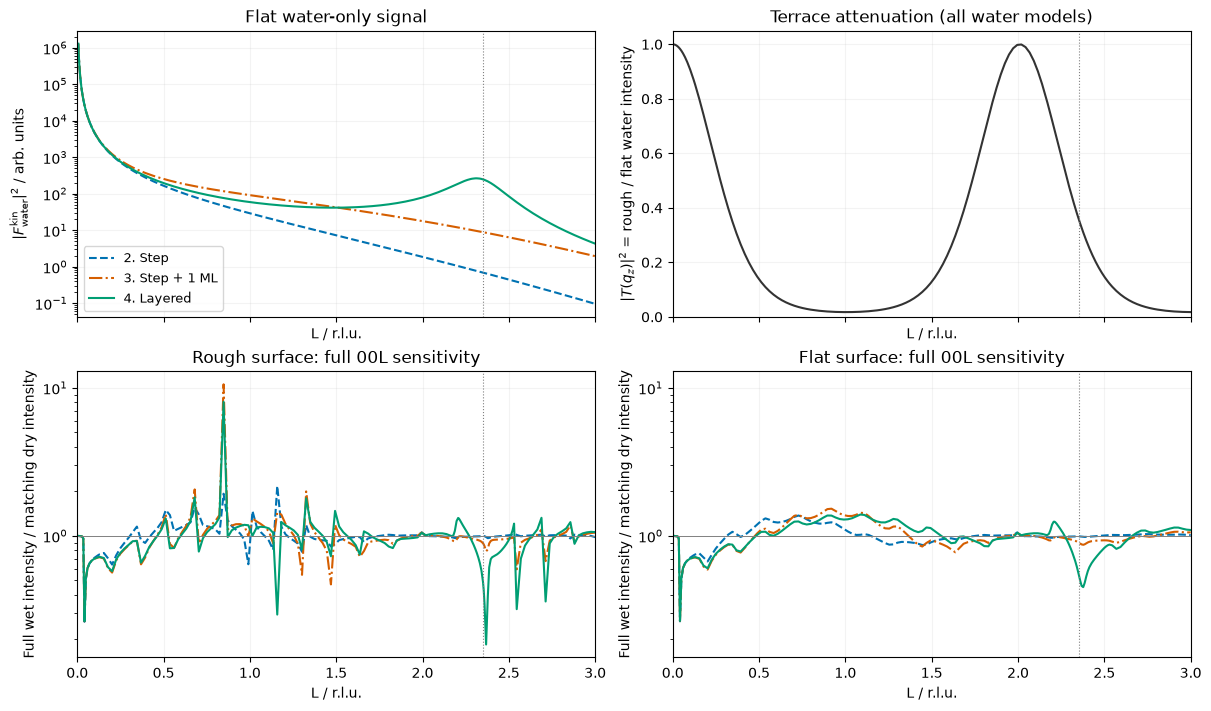

In [5]:
qz = 2*np.pi*L/height
terrace_factor = sum(p*np.exp(1j*qz*(h-mean_height))
                     for h, p in zip(terrace_heights, probabilities))
for label in intrinsic:
    predicted = water_F["Flat", label] * terrace_factor
    np.testing.assert_allclose(water_F["Rough", label], predicted, rtol=1e-7, atol=1e-8)
feature_index = np.argmin(abs(L-layer_L))
attenuation = abs(terrace_factor[feature_index])**2
print(f"At qz=2pi/d (L={L[feature_index]:.5f}): water intensity rough/flat = {attenuation:.4f}")
print(f"Removing terraces increases the isolated water intensity by {1/attenuation:.2f} times there.")

fig_sensitivity, axes_sensitivity = plt.subplots(2, 2, figsize=(12, 7), sharex=True,
                                                constrained_layout=True)
for label, color, style in zip(models, colors, styles):
    if label == "1. Dry":
        continue
    axes_sensitivity[0, 0].semilogy(L, abs(water_F["Flat", label])**2,
                                    color=color, ls=style, label=label)
axes_sensitivity[0, 0].set(title="Flat water-only signal", ylabel=r"$|F_{\rm water}^{\rm kin}|^2$ / arb. units")
axes_sensitivity[0, 0].legend(fontsize=9)
axes_sensitivity[0, 1].plot(L, abs(terrace_factor)**2, color="#333333")
axes_sensitivity[0, 1].set(title="Terrace attenuation (all water models)",
                          ylabel=r"$|T(q_z)|^2$ = rough / flat water intensity", ylim=(0., 1.05))
for column, surface_name in enumerate(("Rough", "Flat")):
    ax = axes_sensitivity[1, column]
    dry_intensity = comparison_intensity[surface_name, 0, 0, "1. Dry"]
    floor = dry_intensity.max()*1e-8
    valid = dry_intensity > floor
    print(f"{surface_name} dry-intensity floor for ratios: {floor:.5g}")
    for label, color, style in zip(models, colors, styles):
        if label == "1. Dry":
            continue
        wet = comparison_intensity[surface_name, 0, 0, label]
        ratio = wet/dry_intensity
        ax.plot(L, np.where(valid, ratio, np.nan), color=color, ls=style, lw=1.5, label=label)
        print(f"  {label}: wet/dry at L={L[feature_index]:.5f} = {ratio[feature_index]:.4f}")
    ax.axhline(1., color="0.5", lw=.7)
    ax.set(title=f"{surface_name} surface: full 00L sensitivity", ylabel="Full wet intensity / matching dry intensity",
           yscale="log")
for ax in axes_sensitivity.flat:
    ax.axvline(layer_L, color="0.5", ls=":", lw=.8)
    ax.set(xlim=(0., 3.), xlabel="L / r.l.u.")
    ax.grid(alpha=.15)
# Identical ratio limits make the two surface sensitivities directly comparable.
ratio_limits = [ax.get_ylim() for ax in axes_sensitivity[1]]
for ax in axes_sensitivity[1]:
    ax.set_ylim(min(v[0] for v in ratio_limits), max(v[1] for v in ratio_limits))
plt.show()


### Result for these default parameters

At the water-layering wavevector ($L=2.35025$), terrace averaging retains
**36.1%** of the isolated water intensity; flattening increases it by **2.77×**.
The full layered wet/dry CTR ratios are **0.488 on the rough surface**
and **0.558 on the flat surface**. For the adsorbed-monolayer cases the
ratios are **0.891** and **0.902**, respectively.

Terrace roughness suppresses the direct water signal in a momentum-dependent
way, but it does not make this example's full CTR insensitive to water.
The solid signal and coherent interference change too. Ratios near deep dry
minima are not universal sensitivity measures; experimental detection limits
also require uncertainties and instrumental resolution.

These curves use the analytic interface / constant-medium DWBA approximation.
Adsorption and molecular layering enter the perturbation, not the optical
profile. Use explicit numerical erf confirmation to assess that approximation
for step models.
